# In-loop photodiode gain and LCVR power stabilisation

Compare two PDA36A2 analogue gain settings at the **same mean laser power, Moku input range and loop response**. Increasing the PDA gain makes a given change in laser power produce more voltage before the Moku digitises it. The same Moku voltage noise then represents a smaller fractional power error, so the feedback injects less real power noise.

The example uses illustrative spectra and an integral loop with **5 Hz unity gain**. It omits detailed LCVR dynamics, PDA noise and changes in optical transmission between the pickoff and the cell. Edit the parameters and rerun all cells to explore the model. Requires NumPy and Matplotlib.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots 
plt.style.use(["science", "no-latex"])# Editable settings
pda_gain_step_db = 30.0
in_loop_optical_dc_v = 1.0      # Dark-subtracted DC at the original PDA gain
out_loop_optical_dc_v = 1.0     # Dark-subtracted DC on the witness detector
unity_gain_hz = 5.0
free_running_asd_at_1hz = 60e-6  # Fractional laser power ASD [1/√Hz]
moku_asd_at_1hz = 30e-6         # In-loop Moku input noise ASD [V/√Hz]
witness_asd_at_1hz = 18e-6      # Out-of-loop electronics ASD [V/√Hz]

gain_factor = 10 ** (pda_gain_step_db / 20)
higher_gain_dc_v = in_loop_optical_dc_v * gain_factor

print(f"PDA voltage gain factor: {gain_factor:.3f}×")
print(f"In-loop optical DC: {in_loop_optical_dc_v:.3f} V → {higher_gain_dc_v:.3f} V")
print(f"To preserve the loop response, multiply the controller gain by {1 / gain_factor:.3f}.")

PDA voltage gain factor: 31.623×
In-loop optical DC: 1.000 V → 31.623 V
To preserve the loop response, multiply the controller gain by 0.032.


## Noise that reaches the atoms



For open-loop gain $L(f)=f_u/(jf)$, the free-running noise couples through $|1/(1+L)|$. The in-loop Moku voltage noise couples to the actual laser power through $|L/(1+L)|$ after conversion to fractional units by dividing by the in-loop optical DC voltage $V_{\rm PD}$.

$$
A_{\rm locked}^2 =
\left|\frac{1}{1+L}\right|^2 A_{\rm free}^2
+
\left|\frac{L}{1+L}\right|^2
\left(\frac{A_{\rm Moku}}{V_{\rm PD}}\right)^2.
$$

Independent noise contributions add in quadrature. The witness detector adds its own independent noise to $A_{\rm locked}$. Its readout settings are held fixed in both cases.

In [20]:
def noise_model(frequency_hz, detector_dc_v):
    """Return fractional power ASDs for the laser and witness at positive frequencies."""
    # Illustrative 1/f PSDs, so each ASD scales as 1/√f.
    shape = 1 / np.sqrt(frequency_hz)
    loop_gain = unity_gain_hz / (1j * frequency_hz)

    free = free_running_asd_at_1hz * shape
    residual_free = free / np.abs(1 + loop_gain)
    injected_moku = (
        np.abs(loop_gain / (1 + loop_gain))
        * moku_asd_at_1hz * shape / detector_dc_v
    )
    locked = np.hypot(residual_free, injected_moku)
    witness_floor = witness_asd_at_1hz * shape / out_loop_optical_dc_v


    return {
        "free": free,
        "residual_free": residual_free,
        "injected_moku": injected_moku,
        "locked": locked,
        "witness_floor": witness_floor,
        "witness": np.hypot(locked, witness_floor),
    }


original_at_1hz = noise_model(1.0, in_loop_optical_dc_v)
higher_at_1hz = noise_model(1.0, higher_gain_dc_v)
print(f"{'ASD at 1 Hz [ppm/√Hz]':36} {'Original gain':>14} {'Changed gain':>14}")
for label, key in [
    ("Moku contribution to laser noise", "injected_moku"),
    ("Actual stabilised laser noise", "locked"),
    ("Out-of-loop measured noise", "witness"),
]:
    print(f"{label:36} {original_at_1hz[key] * 1e6:14.1f} {higher_at_1hz[key] * 1e6:14.1f}")

ASD at 1 Hz [ppm/√Hz]                 Original gain   Changed gain
Moku contribution to laser noise               29.4            0.9
Actual stabilised laser noise                  31.7           11.8
Out-of-loop measured noise                     36.4           21.5


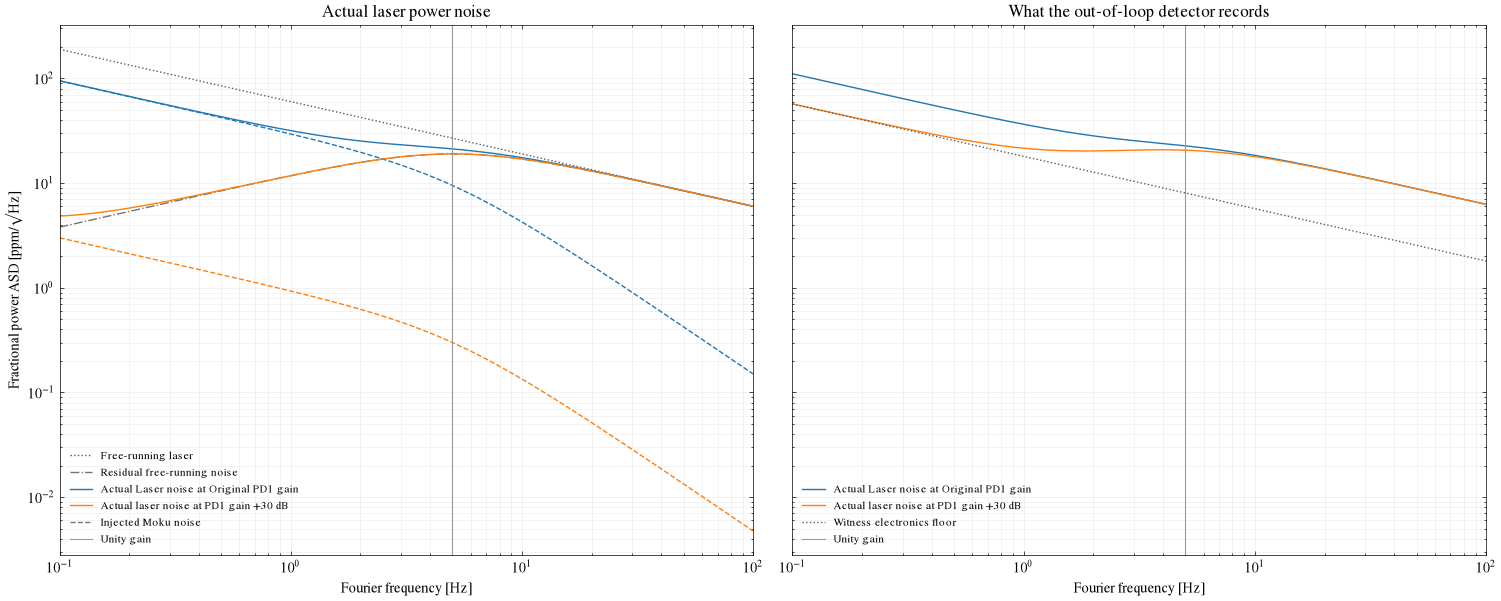

In [21]:
frequency = np.geomspace(0.1, 100, 501)
original = noise_model(frequency, in_loop_optical_dc_v)
higher_gain = noise_model(frequency, higher_gain_dc_v)

fig, (ax_laser, ax_witness) = plt.subplots(
    1, 2, figsize=(15,6), sharey=True, layout="constrained"
)

ax_laser.loglog(frequency, original["free"] * 1e6, ":", color="0.35",
                label="Free-running laser")
ax_laser.loglog(frequency, original["residual_free"] * 1e6, "-.", color="0.45",
                label="Residual free-running noise")
for case, colour, label in [
    (original, "tab:blue", "Actual Laser noise at Original PD1 gain"),
    (higher_gain, "tab:orange", f"Actual laser noise at PD1 gain {pda_gain_step_db:+g} dB"),
]:
    ax_laser.loglog(frequency, case["locked"] * 1e6, color=colour, label=label)
    ax_laser.loglog(frequency, case["injected_moku"] * 1e6, "--", color=colour)
    ax_witness.loglog(frequency, case["witness"] * 1e6, color=colour, label=label)

ax_laser.plot([], [], "--", color="0.45", label="Injected Moku noise")
ax_witness.loglog(frequency, original["witness_floor"] * 1e6, ":",
                  color="0.35", label="Witness electronics floor")

ax_laser.set(title="Actual laser power noise", ylabel="Fractional power ASD [ppm/√Hz]")
ax_witness.set(title="What the out-of-loop detector records")

for ax in (ax_laser, ax_witness):
    ax.axvline(unity_gain_hz, color="0.6", linewidth=0.8, label="Unity gain")
    ax.set(xlabel="Fourier frequency [Hz]", xlim=(0.1, 100))
    ax.grid(True, which="both", alpha=0.20)
    ax.legend(fontsize=8, loc="lower left", framealpha=0.95)

plt.show()

## Compare with your measurement

- **In loop.** After changing PDA gain, set the PID to the voltage at the original optical power. Scale the controller gain by the inverse of the PDA gain change and check the loop response. On the 10 Vpp range, check that the actual PDA voltage, including its offset and excursions, stays within ±5 V.
- **Out of loop.** Keep the witness readout settings fixed. Divide its voltage ASD and its beam-blocked ASD by the same dark-subtracted witness DC voltage to express both in fractional units. The solid curves can approach the witness floor even as the actual laser gets quieter.
- **At the cell.** To include power fluctuations from the delivery fibre, monitor the beam after the fibre and close to the vapour cell.